In [1]:

# RQ2: Influential Node Identification
# Step 1: Load libraries and dataset

import networkx as nx
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the same dataset used in RQ1
G = nx.karate_club_graph()

print("Network loaded successfully!")
print(f"Number of nodes: {G.number_of_nodes()}")
print(f"Number of edges: {G.number_of_edges()}")
print(f"Directed: {G.is_directed()}")
print(f"Connected: {nx.is_connected(G)}")


Network loaded successfully!
Number of nodes: 34
Number of edges: 78
Directed: False
Connected: True


In [4]:

# Degree centrality: number of direct connections
degree = nx.degree_centrality(G_unweighted)

# Betweenness centrality: importance as a bridge
betweenness = nx.betweenness_centrality(
    G_unweighted,
    normalized=True,
    weight=None
)

# PageRank: importance based on connected neighbours
pagerank = nx.pagerank(
    G_unweighted,
    alpha=0.85,
    weight=None
)

# Combine all three measures into one DataFrame
centrality_df = pd.DataFrame({
    "node": list(G_unweighted.nodes()),
    "degree": [
        degree[n] for n in G_unweighted.nodes()
    ],
    "betweenness": [
        betweenness[n] for n in G_unweighted.nodes()
    ],
    "pagerank": [
        pagerank[n] for n in G_unweighted.nodes()
    ]
})

# Sort by degree centrality
centrality_df = centrality_df.sort_values(
    by="degree",
    ascending=False
).reset_index(drop=True)

display(centrality_df.head(10))


,node,degree,betweenness,pagerank
0,33,0.515152,0.304075,0.100918
1,0,0.484848,0.437635,0.097002
2,32,0.363636,0.145247,0.071692
3,2,0.303030,0.143657,0.057078
4,1,0.272727,0.053937,0.052878
5,3,0.181818,0.011909,0.035861
6,31,0.181818,0.138276,0.037157
7,23,0.151515,0.017614,0.031521
8,8,0.151515,0.055927,0.029765
9,13,0.151515,0.045863,0.029536


In [5]:

# Step 2.2: Comparing top 10 nodes across centrality measures

top_k = 10

top_degree = (
    centrality_df.nlargest(top_k, "degree")["node"].tolist()
)

top_betweenness = (
    centrality_df.nlargest(top_k, "betweenness")["node"].tolist()
)

top_pagerank = (
    centrality_df.nlargest(top_k, "pagerank")["node"].tolist()
)

ranking_comparison = pd.DataFrame({
    "Rank": range(1, top_k + 1),
    "Degree": top_degree,
    "Betweenness": top_betweenness,
    "PageRank": top_pagerank
})

display(ranking_comparison)

# Compare overlap among the top 10 nodes
print("\nTop 10 overlap:")
print(
    "Degree vs Betweenness:",
    len(set(top_degree) & set(top_betweenness))
)
print(
    "Degree vs PageRank:",
    len(set(top_degree) & set(top_pagerank))
)
print(
    "Betweenness vs PageRank:",
    len(set(top_betweenness) & set(top_pagerank))
)


,Rank,Degree,Betweenness,PageRank
0,1,33,0,33
1,2,0,33,0
2,3,32,32,32
3,4,2,2,2
4,5,1,31,1
5,6,3,8,31
6,7,31,1,3
7,8,23,13,23
8,9,8,19,8
9,10,13,5,13



Top 10 overlap:
Degree vs Betweenness: 8
Degree vs PageRank: 10
Betweenness vs PageRank: 8


Spearman Rank Correlation Matrix:


,degree,betweenness,pagerank
degree,1.0000,0.9049,0.9788
betweenness,0.9049,1.0000,0.8794
pagerank,0.9788,0.8794,1.0000


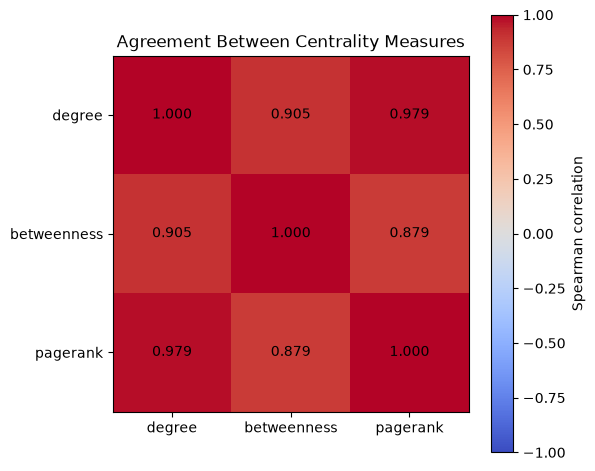

In [6]:

# Step 2.3: Spearman rank correlation

from scipy.stats import spearmanr

measures = ["degree", "betweenness", "pagerank"]

# Calculate correlations across all 34 nodes
correlation_matrix = centrality_df[measures].corr(
    method="spearman"
)

print("Spearman Rank Correlation Matrix:")
display(correlation_matrix.round(4))

# Visualise the correlation matrix
fig, ax = plt.subplots(figsize=(6, 5))

im = ax.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(measures)))
ax.set_yticks(range(len(measures)))
ax.set_xticklabels(measures)
ax.set_yticklabels(measures)

for i in range(len(measures)):
    for j in range(len(measures)):
        ax.text(
            j, i,
            f"{correlation_matrix.iloc[i, j]:.3f}",
            ha="center",
            va="center",
            color="black"
        )

plt.colorbar(im, ax=ax, label="Spearman correlation")
plt.title("Agreement Between Centrality Measures")
plt.tight_layout()
plt.show()


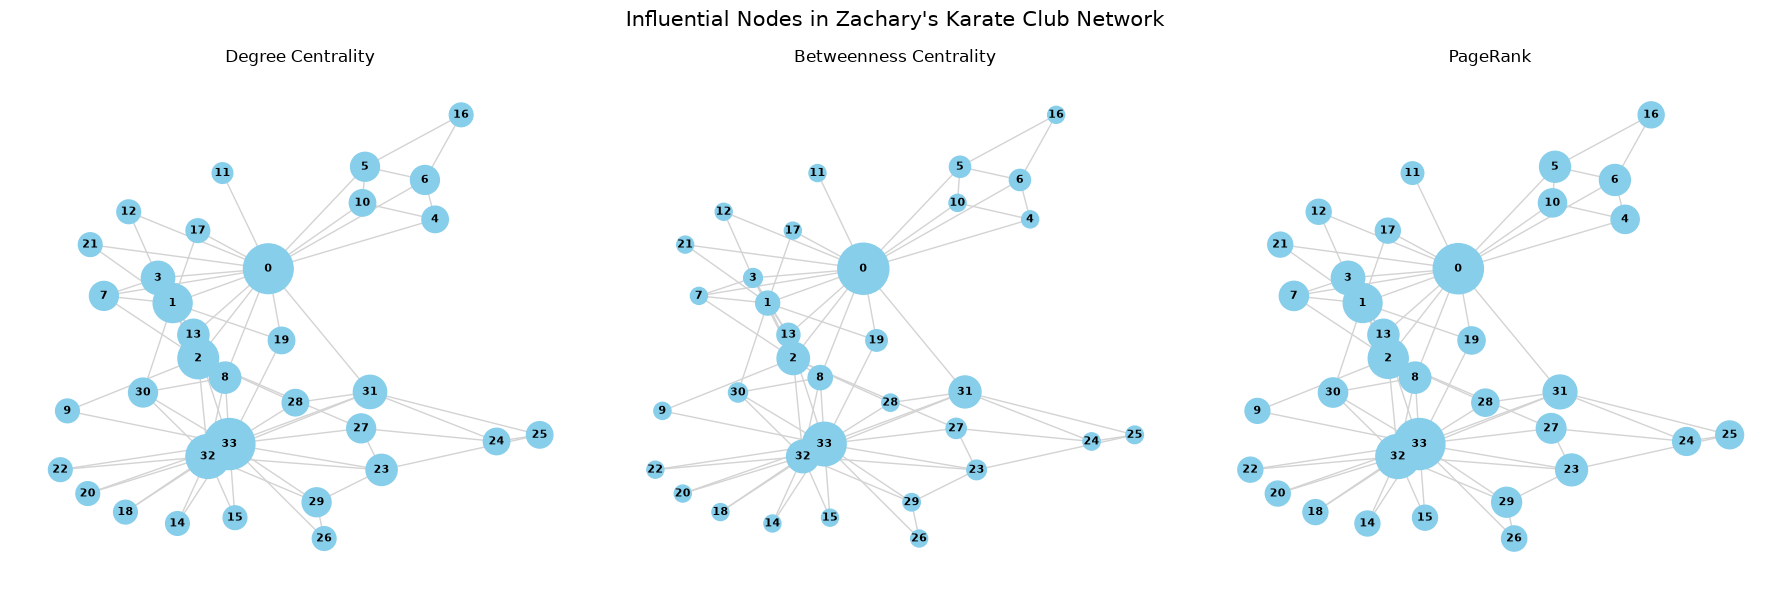

In [7]:

# Step 2.4: Visualise centrality measures

measures = {
    "Degree Centrality": degree,
    "Betweenness Centrality": betweenness,
    "PageRank": pagerank
}

# Keep positions consistent across all three plots
pos = nx.spring_layout(G_unweighted, seed=42)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (name, scores) in zip(axes, measures.items()):

    node_sizes = [
        150 + scores[n] / max(scores.values()) * 1200
        for n in G_unweighted.nodes()
    ]

    nx.draw_networkx(
        G_unweighted,
        pos=pos,
        ax=ax,
        node_size=node_sizes,
        node_color="skyblue",
        edge_color="lightgray",
        with_labels=True,
        font_size=8,
        font_weight="bold"
    )

    ax.set_title(name)
    ax.axis("off")

plt.suptitle(
    "Influential Nodes in Zachary's Karate Club Network",
    fontsize=15
)

plt.tight_layout()
plt.show()


In [8]:

# Step 2.5: Connect influence analysis to Louvain communities

# Reproduce a Louvain partition using seed 42
louvain_communities = nx.community.louvain_communities(
    G_unweighted,
    seed=42,
    weight=None
)

# Assign each node to its detected community
community_map = {}

for community_id, members in enumerate(louvain_communities):
    for node in members:
        community_map[node] = community_id

# Add community membership to our centrality table
centrality_df["community"] = centrality_df["node"].map(
    community_map
)

print("Number of Louvain communities:", len(louvain_communities))

print("\nCommunity sizes:")
for community_id, members in enumerate(louvain_communities):
    print(f"Community {community_id}: {len(members)} nodes")

print("\nTop 10 influential nodes and their communities:")
display(
    centrality_df[
        ["node", "community", "degree", "betweenness", "pagerank"]
    ].head(10)
)


Number of Louvain communities: 3

Community sizes:
Community 0: 17 nodes
Community 1: 4 nodes
Community 2: 13 nodes

Top 10 influential nodes and their communities:


,node,community,degree,betweenness,pagerank
0,33,2,0.515152,0.304075,0.100918
1,0,0,0.484848,0.437635,0.097002
2,32,2,0.363636,0.145247,0.071692
3,2,0,0.303030,0.143657,0.057078
4,1,0,0.272727,0.053937,0.052878
5,3,0,0.181818,0.011909,0.035861
6,31,1,0.181818,0.138276,0.037157
7,23,2,0.151515,0.017614,0.031521
8,8,2,0.151515,0.055927,0.029765
9,13,0,0.151515,0.045863,0.029536


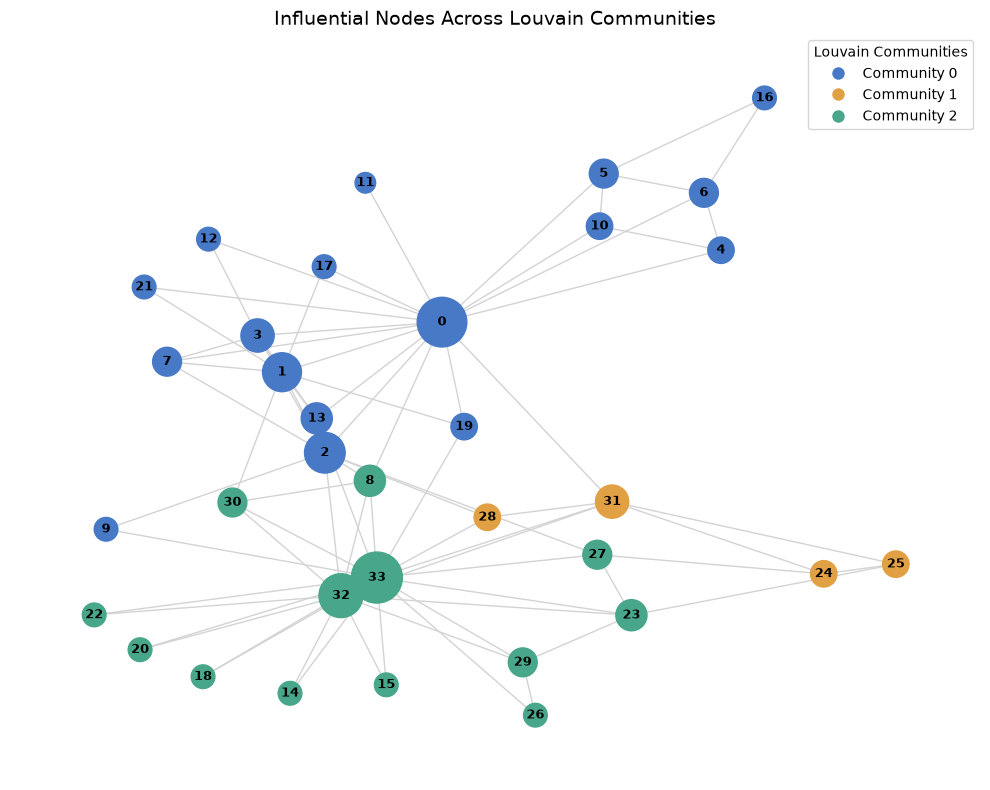

In [9]:

# Step 2.6: Visualise communities and influential nodes

from matplotlib.lines import Line2D

community_colors = {
    0: "#4779C6",
    1: "#E2A044",
    2: "#48A68B"
}

node_colors = [
    community_colors[community_map[n]]
    for n in G_unweighted.nodes()
]

node_sizes = [
    150 + degree[n] / max(degree.values()) * 1200
    for n in G_unweighted.nodes()
]

fig, ax = plt.subplots(figsize=(10, 8))

nx.draw_networkx(
    G_unweighted,
    pos=pos,
    ax=ax,
    node_color=node_colors,
    node_size=node_sizes,
    edge_color="lightgray",
    with_labels=True,
    font_size=9,
    font_weight="bold"
)

legend_elements = [
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        label=f"Community {i}",
        markerfacecolor=community_colors[i],
        markersize=10
    )
    for i in sorted(community_colors)
]

ax.legend(
    handles=legend_elements,
    loc="upper right",
    title="Louvain Communities"
)

ax.set_title(
    "Influential Nodes Across Louvain Communities",
    fontsize=14
)

ax.axis("off")
plt.tight_layout()
plt.show()


In [10]:

# Save RQ2 results

from pathlib import Path

# Assumes Jupyter was launched from the project root
RESULTS_DIR = Path("results")
FIGURES_DIR = Path("figures")

# Also works if Jupyter was launched from notebooks/
if not RESULTS_DIR.exists() and Path("../results").exists():
    RESULTS_DIR = Path("../results")
    FIGURES_DIR = Path("../figures")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

centrality_df.to_csv(
    RESULTS_DIR / "karate_centrality_results.csv",
    index=False
)

ranking_comparison.to_csv(
    RESULTS_DIR / "karate_centrality_rankings.csv",
    index=False
)

correlation_matrix.to_csv(
    RESULTS_DIR / "karate_centrality_correlations.csv"
)

# Save the current community visualisation
fig.savefig(
    FIGURES_DIR / "karate_influence_communities.png",
    dpi=300,
    bbox_inches="tight"
)

print("RQ2 results saved successfully!")
print("Results folder:", RESULTS_DIR.resolve())
print("Figures folder:", FIGURES_DIR.resolve())


RQ2 results saved successfully!
Results folder: C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis\results
Figures folder: C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis\figures


In [12]:

!git status
!git add notebooks/03_influence_analysis.ipynb results/ figures/
!git commit -m "Complete RQ2 centrality and community influence analysis"
!git push


On branch main
Your branch is up to date with 'origin/main'.

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   01_data_exploration.ipynb
	modified:   02_community_detection.ipynb

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	../figures/karate_influence_communities.png
	03_influence_analysis.ipynb
	../results/karate_centrality_correlations.csv
	../results/karate_centrality_rankings.csv
	../results/karate_centrality_results.csv

no changes added to commit (use "git add" and/or "git commit -a")


fatal: pathspec 'notebooks/03_influence_analysis.ipynb' did not match any files


On branch main
Your branch is up to date with 'origin/main'.

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   01_data_exploration.ipynb
	modified:   02_community_detection.ipynb

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	../figures/karate_influence_communities.png
	03_influence_analysis.ipynb
	../results/karate_centrality_correlations.csv
	../results/karate_centrality_rankings.csv
	../results/karate_centrality_results.csv

no changes added to commit (use "git add" and/or "git commit -a")


Everything up-to-date
